# Which Recalls Do Owner Complaints Actually Warn Us About?
**MSDS 692 Data Science Practicum · Apurba Poudel · Regis University**

**Recommendation:** NHTSA should investigate as soon as complaints pile up on one vehicle. Most recalls come with no warning, but when owners do warn, it's about two years early.

## Setup
Run this once if the packages aren't installed yet (remove the `#` first).

In [1]:
# !pip install pandas numpy scipy lifelines scikit-learn matplotlib

In [2]:
from pathlib import Path

# Folder holding the three NHTSA .txt files
DATA_DIR = Path(r'/Users/oxy/Desktop/MSDS/prac 1/Data')

COMPLAINT_FILES = ["COMPLAINTS_RECEIVED_2010-2014.txt", "COMPLAINTS_RECEIVED_2015-2019.txt"]
RECALL_FILE = "FLAT_RCL_POST_2010.txt"

OUTPUT_DIR = Path("output")   
RUN_SLOW_STEPS = True
N_BOOT_HR = 150               

In [3]:

import time, json, warnings
warnings.filterwarnings("ignore")
missing = [f for f in COMPLAINT_FILES + [RECALL_FILE] if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Can't find {missing} in {DATA_DIR.resolve()}. Fix DATA_DIR in the Settings cell.")
for f in COMPLAINT_FILES + [RECALL_FILE]:
    print(f"found {f:36s} {(DATA_DIR / f).stat().st_size / 1e6:6.0f} MB")
OUTPUT_DIR.mkdir(exist_ok=True)
R = {}                 # every result goes in here, then into results.json
T0 = time.time()

found COMPLAINTS_RECEIVED_2010-2014.txt       313 MB
found COMPLAINTS_RECEIVED_2015-2019.txt       357 MB
found FLAT_RCL_POST_2010.txt                  311 MB


## Step 1 · Load the data
The files are tab-delimited with no header row, so columns are picked by position.
I checked the positions against the data itself: column 16 is the date NHTSA received the complaint
(its values sit exactly inside each file's window), and column 7, the failure date, is unusable
(values run from year 1015 to 2160). The full files are read; nothing is sampled. Then the code keeps
vehicles only and plausible model years (1980–2021).

In [4]:
"""Load the three NHTSA ODI flat files.

The files are tab-delimited with no header row. Column positions were
checked against the data itself, not only the layout documents:
  - column 16 is the date NHTSA received the complaint; its values sit
    exactly inside each file's window (e.g. 2015-01-01 to 2019-12-31)
  - column 7 (failure date) is unusable: values run from year 1015 to 2160
"""
import csv
import pandas as pd

COMPLAINT_COLS = {0: "CMPLID", 3: "MAKE", 4: "MODEL", 5: "YEAR", 6: "CRASH",
                  8: "FIRE", 9: "INJURED", 10: "DEATHS", 11: "COMPDESC",
                  16: "LDATE", 19: "CDESCR", 45: "PROD_TYPE"}
RECALL_COLS = {1: "CAMPNO", 2: "MAKE", 3: "MODEL", 4: "YEAR", 6: "COMPNAME",
               10: "RCLTYPECD", 13: "INFLUENCED_BY", 15: "RCDATE", 18: "FMVSS"}


def _read(path, cols):
    df = pd.read_csv(path, sep="\t", header=None, encoding="latin-1",
                     quoting=csv.QUOTE_NONE, usecols=sorted(cols),
                     low_memory=False, on_bad_lines="skip", dtype=str)
    df.columns = [cols[i] for i in sorted(cols)]
    return df


def make_key(df, comp_col):
    """make | model | model year | component, upper-cased."""
    # fillna("nan") keeps pandas 2 and 3 identical: pandas 2 turned a missing value
    # into the text "nan"; pandas 3 keeps it missing, and the whole key drops out
    up = lambda s: s.fillna("nan").astype(str).str.strip().str.upper()
    yr = pd.to_numeric(df["YEAR"], errors="coerce")
    return (up(df["MAKE"]) + "|" + up(df["MODEL"]) + "|"
            + yr.astype("Int64").astype(str).fillna("<NA>") + "|" + up(df[comp_col]))


def load_complaints(paths):
    parts = []
    for p in paths:
        d = _read(p, COMPLAINT_COLS)
        print(f"  read {len(d):,} rows from {p.name}")
        parts.append(d)
    raw = pd.concat(parts, ignore_index=True)
    df = raw[raw["PROD_TYPE"] == "V"].copy()                  # vehicles only
    df["received"] = pd.to_datetime(df["LDATE"], format="%Y%m%d", errors="coerce")
    df["yr"] = pd.to_numeric(df["YEAR"], errors="coerce")
    df = df[df["yr"].between(1980, 2021)].copy()               # drops 9999 and the like
    df["KEY"] = make_key(df, "COMPDESC")
    df["top_comp"] = df["COMPDESC"].fillna("nan").astype(str).str.upper().str.split(":").str[0].str.strip()
    df["make_up"] = df["MAKE"].fillna("nan").astype(str).str.strip().str.upper()
    df["narr_len"] = df["CDESCR"].fillna("nan").astype(str).str.len()
    counts = {"complaint_rows": int(len(raw)), "vehicle_complaints": int((raw["PROD_TYPE"] == "V").sum()),
              "vehicle_complaints_valid_year": int(len(df))}
    return df, counts


def load_recalls(path):
    raw = _read(path, RECALL_COLS)
    print(f"  read {len(raw):,} rows from {path.name}")
    df = raw[raw["RCLTYPECD"] == "V"].copy()
    df["recall_date"] = pd.to_datetime(df["RCDATE"], format="%Y%m%d", errors="coerce")
    df["KEY"] = make_key(df, "COMPNAME")
    df = df.dropna(subset=["recall_date"])
    return df, {"recall_rows": int(len(raw)), "vehicle_recall_rows": int(len(df))}

In [5]:
complaints, c_counts = load_complaints([DATA_DIR / f for f in COMPLAINT_FILES])
recalls, r_counts = load_recalls(DATA_DIR / RECALL_FILE)
per_year = complaints.groupby(complaints["received"].dt.year).size()
R["data"] = {**c_counts, **r_counts, "per_year": {int(k): int(v) for k, v in per_year.items()}}
print(f"vehicle complaints with a valid model year: {c_counts['vehicle_complaints_valid_year']:,}")
print(f"vehicle recall rows: {r_counts['vehicle_recall_rows']:,}")
per_year

  read 392,970 rows from COMPLAINTS_RECEIVED_2010-2014.txt
  read 489,809 rows from COMPLAINTS_RECEIVED_2015-2019.txt
  read 245,008 rows from FLAT_RCL_POST_2010.txt
vehicle complaints with a valid model year: 863,352
vehicle recall rows: 218,265


received
2010     79034
2011     60941
2012     56101
2013     71906
2014    111771
2015    103878
2016     94473
2017     90374
2018     89879
2019    104995
dtype: int64

## Step 2 · One row per vehicle-and-part case
A case is one make, model, model year and component. Every input comes from the **first six months**
after the case's first complaint. That fixed window is the leakage control: a case that took 40 months
to recall had 40 months to collect complaints, so using every complaint before the recall would leak the answer.

In [6]:
"""One row per make | model | year | component ("group" or "case").

Every feature comes from complaints in the FIRST SIX MONTHS after the
group's first complaint. A fixed window stops features from growing with
the outcome: a group that took 40 months to recall had 40 months to
collect complaints, so using every pre-recall complaint would leak the answer.
"""
import numpy as np
import pandas as pd

WINDOW_MONTHS = 6
CENSOR_DATE = pd.Timestamp("2026-08-28")   # last recall date in the file


def early_window(complaints):
    c = complaints.copy()
    c["first"] = c.groupby("KEY")["received"].transform("min")
    c["months_in"] = (c["received"] - c["first"]).dt.days / 30.44
    return c[c["months_in"] <= WINDOW_MONTHS]


def build_groups(complaints, recalls):
    early = early_window(complaints)
    num = lambda s: pd.to_numeric(s, errors="coerce").fillna(0)
    g = early.groupby("KEY").agg(
        first=("first", "first"),
        n_early=("CMPLID", "size"),
        crash=("CRASH", lambda s: (s == "Y").mean()),
        fire=("FIRE", lambda s: (s == "Y").mean()),
        injury=("INJURED", lambda s: (num(s) > 0).mean()),
        death=("DEATHS", lambda s: float((num(s) > 0).max())),
        narr_len=("narr_len", "mean"),
        model_year=("yr", "first"),
        make=("make_up", "first"),
        top_comp=("top_comp", "first"),
    )
    g["age"] = (g["first"].dt.year - g["model_year"]).clip(-2, 25)

    # first recall on each group, and who drove it
    first_rcl = (recalls.sort_values("recall_date").drop_duplicates("KEY")
                 .set_index("KEY")[["recall_date", "INFLUENCED_BY", "CAMPNO"]])
    g = g.join(first_rcl)

    g["t_event"] = (g["recall_date"] - g["first"]).dt.days / 30.44
    g["recalled"] = g["recall_date"].notna() & (g["t_event"] > 0)
    # route: 0 = no recall yet (still waiting), 1 = company, 2 = NHTSA pushed it (ODI)
    g["route"] = np.where(~g["recalled"], 0, np.where(g["INFLUENCED_BY"] == "ODI", 2, 1))
    g["dur"] = np.where(g["recalled"], g["t_event"], (CENSOR_DATE - g["first"]).dt.days / 30.44)
    g = g[g["dur"] > 0.5].copy()
    g["recalled_36mo"] = (g["recalled"] & (g["t_event"] <= 36)).astype(int)
    return g


def early_text(complaints, max_chars=6000):
    """All early-window narratives for each group, joined, for the text model."""
    early = early_window(complaints)
    return early.groupby("KEY")["CDESCR"].apply(lambda s: " ".join(s.fillna("nan").astype(str))[:max_chars])

In [7]:
g = build_groups(complaints, recalls)
R["data"]["cases"] = int(len(g))
R["data"]["still_waiting_pct"] = round(float((g["route"] == 0).mean() * 100), 1)
print(f"{len(g):,} cases | company recalls {(g.route == 1).sum():,} | NHTSA-pushed {(g.route == 2).sum():,}"
      f" | still waiting {R['data']['still_waiting_pct']}%")
g.head()

133,053 cases | company recalls 1,308 | NHTSA-pushed 665 | still waiting 98.5%


,first,n_early,crash,fire,injury,death,narr_len,model_year,make,top_comp,age,recall_date,INFLUENCED_BY,CAMPNO,t_event,recalled,route,dur,recalled_36mo
KEY,,,,,,,,,,,,,,,,,,,
3 TON UTILITY|3EC14|2003|STRUCTURE,2010-06-18,1,0.0,0.0,0.0,0.0,1878.0,2003.0,3 TON UTILITY,STRUCTURE,7.0,NaT,NaN,NaN,NaN,False,0,194.316689,0
3 TON UTILITY|3EC14|2003|TRAILER HITCHES,2010-06-18,1,0.0,0.0,0.0,0.0,1878.0,2003.0,3 TON UTILITY,TRAILER HITCHES,7.0,NaT,NaN,NaN,NaN,False,0,194.316689,0
4 TON UTILITY|4EC16W|2001|ELECTRONIC STABILITY CONTROL (ESC),2015-08-27,1,1.0,0.0,0.0,0.0,636.0,2001.0,4 TON UTILITY,ELECTRONIC STABILITY CONTROL (ESC),14.0,NaT,NaN,NaN,NaN,False,0,132.030223,0
4 TON UTILITY|4EC16W|2001|STEERING,2015-08-27,1,1.0,0.0,0.0,0.0,636.0,2001.0,4 TON UTILITY,STEERING,14.0,NaT,NaN,NaN,NaN,False,0,132.030223,0
4 TON UTILITY|4EC16W|2001|VEHICLE SPEED CONTROL,2015-08-27,1,1.0,0.0,0.0,0.0,636.0,2001.0,4 TON UTILITY,VEHICLE SPEED CONTROL,14.0,NaT,NaN,NaN,NaN,False,0,132.030223,0


## Step 3 · How often did owners complain before a recall?
Counted **once per recall campaign** (one campaign can cover dozens of vehicle lines), defect recalls only,
2016–2019. Confidence intervals come from 2,000 bootstrap resamples.

In [8]:
"""How often owners complained BEFORE a recall, by route.

Counted once per recall campaign: one campaign can cover dozens of vehicle
lines, and counting each line separately lets a few huge campaigns swamp
the rate. Defect recalls only: compliance recalls (FMVSS set) are labels
and paperwork that owners don't complain about.
"""
import numpy as np


def warning_by_campaign(complaints, recalls, start=2016, end=2019):
    first_complaint = complaints.groupby("KEY")["received"].min()
    r = recalls[recalls["recall_date"].dt.year.between(start, end)
                & recalls["FMVSS"].isna()].drop_duplicates(["CAMPNO", "KEY"]).copy()
    r["prior"] = r["KEY"].map(first_complaint) < r["recall_date"]
    r["airbag"] = r["KEY"].str.split("|").str[3].str.startswith("AIR BAGS")
    camp = r.groupby("CAMPNO").agg(route=("INFLUENCED_BY", "first"),
                                   prior=("prior", "max"), airbag=("airbag", "max"))
    return camp[camp["route"].isin(["MFR", "ODI"])]


def _boot_rate(p, rng, n_boot):
    return [rng.choice(p, len(p)).mean() for _ in range(n_boot)]


def summarize(camp, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    out = {"overall": {"n": int(len(camp)), "n_prior": int(camp["prior"].sum()),
                       "rate": round(float(camp["prior"].mean() * 100), 1)}}
    for route in ["ODI", "MFR"]:
        p = camp.loc[camp["route"] == route, "prior"].values.astype(float)
        b = _boot_rate(p, rng, n_boot)
        out[route] = {"n": int(len(p)), "rate": round(p.mean() * 100, 1),
                      "lo": round(np.percentile(b, 2.5) * 100, 1),
                      "hi": round(np.percentile(b, 97.5) * 100, 1)}
    gaps = []
    rng = np.random.default_rng(seed)        # the gap gets its own fixed stream
    for _ in range(n_boot):
        s = camp.sample(len(camp), replace=True, random_state=int(rng.integers(1e9)))
        m = s.groupby("route")["prior"].mean()
        gaps.append((m["ODI"] - m["MFR"]) * 100)
    out["gap"] = {"mean": round(float(np.mean(gaps)), 1), "lo": round(float(np.percentile(gaps, 2.5)), 1),
                  "hi": round(float(np.percentile(gaps, 97.5)), 1)}
    return out

In [9]:
camp = warning_by_campaign(complaints, recalls)
R["warning"] = summarize(camp)
R["warning"]["no_airbags"] = summarize(camp[~camp["airbag"]])
w = R["warning"]
print(f"overall: {w['overall']['rate']}% ({w['overall']['n_prior']} of {w['overall']['n']})")
print(f"NHTSA-pushed: {w['ODI']['rate']}% [{w['ODI']['lo']}, {w['ODI']['hi']}]")
print(f"company:      {w['MFR']['rate']}% [{w['MFR']['lo']}, {w['MFR']['hi']}]")
print(f"gap: {w['gap']['mean']} points [{w['gap']['lo']}, {w['gap']['hi']}]")
print(f"without air bags: NHTSA {w['no_airbags']['ODI']['rate']}% | company {w['no_airbags']['MFR']['rate']}%")

overall: 8.2% (229 of 2776)
NHTSA-pushed: 19.0% [13.7, 24.9]
company:      7.4% [6.4, 8.4]
gap: 11.5 points [6.1, 17.2]
without air bags: NHTSA 29.1% | company 7.1%


## Step 4 · How long do recalls take, and how long have unrecalled cases been waiting?

In [10]:
"""How long recalls take, and how long unrecalled cases have been waiting."""
import numpy as np
from scipy.stats import mannwhitneyu


def timing_by_route(g, drop_airbags=False):
    r = g[g["recalled"]]
    if drop_airbags:
        r = r[r["top_comp"] != "AIR BAGS"]
    a = r.loc[r["route"] == 1, "t_event"]; b = r.loc[r["route"] == 2, "t_event"]
    return {"MFR": {"n": int(len(a)), "median": round(float(a.median()), 1)},
            "ODI": {"n": int(len(b)), "median": round(float(b.median()), 1)},
            "p": round(float(mannwhitneyu(a, b).pvalue), 3)}


def cumulative_share(g, months=120):
    """Share of each route's recalls that had arrived by each month (0..months)."""
    r = g[g["recalled"]]
    out = {}
    for code, name in [(1, "MFR"), (2, "ODI")]:
        t = np.sort(r.loc[r["route"] == code, "t_event"].values)
        out[name] = [round(float((t <= m).mean() * 100), 1) for m in range(months + 1)]
    return out


def waiting_by_entry_year(g):
    """For cases with no recall yet: median years waited, by year of first complaint."""
    g = g.assign(entry=g["first"].dt.year)
    w = g[g["route"] == 0].groupby("entry")["dur"].median() / 12
    share = g.groupby("entry")["route"].apply(lambda s: (s == 0).mean() * 100)
    return {"years": [int(y) for y in w.index], "median_years": [round(float(v), 1) for v in w.values],
            "share_waiting": [round(float(share[y]), 1) for y in w.index]}


def old_route_chart(g, months=120):
    """The Week 3 chart I later replaced: each route as a share of ALL cases.
    Its line height reflects how many recalls each route has, not speed."""
    from lifelines import AalenJohansenFitter
    out = {}
    for code, name in [(1, "MFR"), (2, "ODI")]:
        aj = AalenJohansenFitter(calculate_variance=False)
        aj.fit(g["dur"], g["route"], event_of_interest=code)
        cd = aj.cumulative_density_.iloc[:, 0]
        out[name] = [round(float(cd[cd.index <= m].iloc[-1] * 100), 3) for m in range(months + 1)]
    return out

In [11]:
R["timing"] = timing_by_route(g)
R["timing"]["no_airbags"] = timing_by_route(g, drop_airbags=True)
R["timing"]["cdf"] = cumulative_share(g)
R["waiting"] = waiting_by_entry_year(g)
t = R["timing"]
print(f"median months to recall: company {t['MFR']['median']} | NHTSA {t['ODI']['median']} (p = {t['p']})")
print(f"without air bags:        company {t['no_airbags']['MFR']['median']} | NHTSA {t['no_airbags']['ODI']['median']} (p = {t['no_airbags']['p']})")

median months to recall: company 22.0 | NHTSA 25.5 (p = 0.041)
without air bags:        company 21.7 | NHTSA 19.5 (p = 0.464)


## Step 5 · Two survival models, one per route
Why survival analysis and not a yes/no classifier: about 98.5% of cases have no recall **yet**.
A classifier calls them all "no." A survival model counts them as still waiting.
Why two models: a case can end in a company recall, an NHTSA-pushed recall, or neither (competing risks).
A hazard ratio above 1 means a recall comes sooner.

In [12]:
"""Competing-risks survival models, one per recall route.

Why survival and not a yes/no classifier: about 98.5% of cases have no
recall yet. A classifier calls them all 'no'; most are really 'not yet'.
Why two models: the routes behave differently, and one yes/no label
mixes them together. Each route is a cause-specific Cox model with the
other route treated as censored. Air bags are a separate stratum because
the proportional-hazards check flagged them.
"""
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

KEY_VARS = ["complaint_volume_log", "crash_or_fire", "vehicle_age"]


def covariates(g, airbag_as_stratum=True):
    X = pd.DataFrame({
        "complaint_volume_log": np.log1p(g["n_early"]),
        "crash_or_fire": ((g["crash"] > 0) | (g["fire"] > 0)).astype(float),
        "vehicle_age": g["age"],
    }, index=g.index)
    comps = [c for c in g["top_comp"].value_counts().head(6).index if c != "AIR BAGS"]
    for comp in comps:
        X["comp_" + comp.lower().replace(" ", "_")[:14]] = (g["top_comp"] == comp).astype(int)
    X["airbag"] = (g["top_comp"] == "AIR BAGS").astype(int)
    return X


def fit_route(g, route_code, stratify=True):
    d = covariates(g)
    d["dur"] = g["dur"].values
    d["event"] = (g["route"] == route_code).astype(int).values
    m = CoxPHFitter(penalizer=0.1)
    if stratify:
        m.fit(d, duration_col="dur", event_col="event", strata=["airbag"])
    else:
        m.fit(d, duration_col="dur", event_col="event")
    return m, d


def hr_table(m, events):
    s = m.summary
    rows = {v: {"hr": round(float(s.loc[v, "exp(coef)"]), 3),
                "lo": round(float(s.loc[v, "exp(coef) lower 95%"]), 3),
                "hi": round(float(s.loc[v, "exp(coef) upper 95%"]), 3),
                "p": round(float(s.loc[v, "p"]), 4)} for v in KEY_VARS}
    return {"rows": rows, "concordance": round(float(m.concordance_index_), 3), "events": int(events)}


def plain_percent(t):
    """Turn hazard ratios into plain % changes for the slide."""
    r = t["rows"]; ln2 = np.log(2)
    return {"double_complaints": round(float((r["complaint_volume_log"]["hr"] ** ln2 - 1) * 100), 1),
            "vehicle_5yrs_older": round((r["vehicle_age"]["hr"] ** 5 - 1) * 100, 1),
            "crash_or_fire": round((r["crash_or_fire"]["hr"] - 1) * 100, 1)}


def ph_check(g, route_code):
    """Proportional-hazards test on the UNstratified model (the check that flagged air bags)."""
    m, d = fit_route(g, route_code, stratify=False)
    res = proportional_hazard_test(m, d, time_transform="rank")
    return {k: round(float(v), 4) for k, v in res.summary["p"].items()}


def bootstrap_hr(g, route_code, n_boot=150, seed=1):
    rng = np.random.default_rng(seed)
    keep = {"complaint_volume_log": [], "vehicle_age": []}
    for _ in range(n_boot):
        s = g.sample(len(g), replace=True, random_state=int(rng.integers(1e9)))
        try:
            m, _ = fit_route(s, route_code)
            for k in keep:
                keep[k].append(float(m.summary.loc[k, "exp(coef)"]))
        except Exception:
            pass
    return {k: {"mean": round(float(np.mean(v)), 3), "lo": round(float(np.percentile(v, 2.5)), 3),
                "hi": round(float(np.percentile(v, 97.5)), 3), "n": len(v)} for k, v in keep.items()}

In [13]:
R["cox"], R["plain"] = {}, {}
for code_, name in [(1, "company"), (2, "nhtsa")]:
    m, _ = fit_route(g, code_)
    R["cox"][name] = hr_table(m, (g["route"] == code_).sum())
    R["plain"][name] = plain_percent(R["cox"][name])
    print(f"\n{name} route (concordance {R['cox'][name]['concordance']})")
    for k, v in R["cox"][name]["rows"].items():
        print(f"  {k:22s} HR {v['hr']}  95% CI [{v['lo']}, {v['hi']}]  p = {v['p']}")
    print(f"  in plain terms: {R['plain'][name]}")


company route (concordance 0.763)
  complaint_volume_log   HR 1.108  95% CI [1.058, 1.16]  p = 0.0
  crash_or_fire          HR 1.035  95% CI [0.989, 1.084]  p = 0.1376
  vehicle_age            HR 0.988  95% CI [0.984, 0.991]  p = 0.0
  in plain terms: {'double_complaints': 7.4, 'vehicle_5yrs_older': -5.9, 'crash_or_fire': 3.5}

nhtsa route (concordance 0.689)
  complaint_volume_log   HR 1.094  95% CI [1.044, 1.147]  p = 0.0002
  crash_or_fire          HR 1.016  95% CI [0.97, 1.065]  p = 0.4965
  vehicle_age            HR 0.998  95% CI [0.994, 1.001]  p = 0.1669
  in plain terms: {'double_complaints': 6.4, 'vehicle_5yrs_older': -1.0, 'crash_or_fire': 1.6}


## Step 6 · Proportional-hazards check
This is the check that flagged air bags on the NHTSA route, which is why air bags are a separate stratum above.

In [14]:
R["ph_check"] = {name: ph_check(g, code_) for code_, name in [(1, "company"), (2, "nhtsa")]}
for name, res in R["ph_check"].items():
    print(f"{name}: flagged at p < 0.01 -> {[k for k, p in res.items() if p < 0.01] or 'none'}")

company: flagged at p < 0.01 -> none
nhtsa: flagged at p < 0.01 -> ['airbag']


## Step 7 · Case study: 2012 Kia Soul engine

In [15]:
"""Pull one vehicle's complaint history for the case-study slide."""
import pandas as pd


def case_timeline(complaints, recalls, key):
    r = recalls[recalls["KEY"] == key].sort_values("recall_date")
    first_recall = r.iloc[0]
    c = complaints[complaints["KEY"] == key]
    before = c[c["received"] < first_recall["recall_date"]]
    per_year = before.groupby(before["received"].dt.year).size()
    first = c["received"].min()
    return {"key": key, "first_complaint": str(first.date()), "recall_date": str(first_recall["recall_date"].date()),
            "campaign": first_recall["CAMPNO"], "route": first_recall["INFLUENCED_BY"],
            "complaints_before_recall": int(len(before)),
            "months": round((first_recall["recall_date"] - first).days / 30.44, 1),
            "years": [int(y) for y in per_year.index], "counts": [int(v) for v in per_year.values]}

In [16]:
R["kia"] = case_timeline(complaints, recalls, "KIA|SOUL|2012|ENGINE")
R["kia"]

{'key': 'KIA|SOUL|2012|ENGINE',
 'first_complaint': '2012-05-18',
 'recall_date': '2019-02-22',
 'campaign': '19V120000',
 'route': 'ODI',
 'complaints_before_recall': 16,
 'months': 81.2,
 'years': [2012, 2013, 2014, 2015, 2016, 2017, 2018],
 'counts': [1, 1, 2, 1, 2, 2, 7]}

## Step 8 · The old Week 3 chart (appendix A10)
It drew each route as a share of *all* cases, so the line height showed how many recalls each route had, not how fast they came.

In [17]:
R["old_chart"] = old_route_chart(g)
print("done")

done


## Step 9 · Bootstrap the hazard ratios (slow)
Refits both models on resampled data to check the intervals don't depend on the model's own assumptions.

In [18]:
if RUN_SLOW_STEPS:
    R["bootstrap_hr"] = {name: bootstrap_hr(g, code_, n_boot=N_BOOT_HR) for code_, name in [(1, "company"), (2, "nhtsa")]}
    for name, b in R["bootstrap_hr"].items():
        print(name, b)
else:
    print("skipped (RUN_SLOW_STEPS = False)")

company {'complaint_volume_log': {'mean': 1.107, 'lo': 1.088, 'hi': 1.129, 'n': 150}, 'vehicle_age': {'mean': 0.988, 'lo': 0.987, 'hi': 0.988, 'n': 150}}
nhtsa {'complaint_volume_log': {'mean': 1.094, 'lo': 1.075, 'hi': 1.115, 'n': 150}, 'vehicle_age': {'mean': 0.998, 'lo': 0.997, 'hi': 0.998, 'n': 150}}


## Step 10 · The alternative I tested and set aside: a yes/no classifier (appendix A4)
Predicts a recall within 36 months. Trained on cases first complained about before 2017, tested on 2017–2019, scored by PR-AUC against the base rate.

In [19]:
"""The alternative I tested and set aside: a yes/no classifier.

Target: recalled within 36 months of the first complaint. Temporal split:
train on cases first complained about before 2017, test on 2017-2019.
Scored by average precision (PR-AUC) against the base rate, because
accuracy is meaningless when about 1% of cases are positive.
"""
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler


def structured(g):
    X = pd.DataFrame({"log_n": np.log1p(g["n_early"]), "crash": g["crash"], "fire": g["fire"],
                      "injury": g["injury"], "death": g["death"], "log_narr": np.log1p(g["narr_len"]),
                      "age": g["age"]}, index=g.index)
    for c in g["top_comp"].value_counts().head(10).index:
        X["C_" + c[:16]] = (g["top_comp"] == c).astype(int)
    for mk in g["make"].value_counts().head(12).index:
        X["M_" + mk[:12]] = (g["make"] == mk).astype(int)
    return X


def compare(g, text):
    X = structured(g); y = g["recalled_36mo"].values
    tr = (g["first"] < "2017-01-01").values; te = ~tr
    base = float(y[te].mean())
    sc = StandardScaler().fit(X[tr]); Xs = sc.transform(X)
    scores = {}
    lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xs[tr], y[tr])
    scores["Logistic regression"] = lr.predict_proba(Xs[te])[:, 1]
    gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, class_weight="balanced",
                                        random_state=0).fit(X[tr], y[tr])
    scores["Gradient boosting"] = gb.predict_proba(X[te])[:, 1]
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=0).fit(X[tr], y[tr])
    scores["Random forest"] = rf.predict_proba(X[te])[:, 1]

    t = text.reindex(g.index).fillna("")
    tv = TfidfVectorizer(max_features=3000, min_df=20, stop_words="english", ngram_range=(1, 2), sublinear_tf=True)
    Ttr = tv.fit_transform(t[tr]); Tte = tv.transform(t[te])
    lt = LogisticRegression(max_iter=1500, class_weight="balanced").fit(Ttr, y[tr])
    scores["Complaint text (TF-IDF)"] = lt.predict_proba(Tte)[:, 1]
    Atr = sp.hstack([sp.csr_matrix(Xs[tr]), Ttr]).tocsr(); Ate = sp.hstack([sp.csr_matrix(Xs[te]), Tte]).tocsr()
    la = LogisticRegression(max_iter=2500, class_weight="balanced").fit(Atr, y[tr])
    scores["Text + structured features"] = la.predict_proba(Ate)[:, 1]

    models = []
    for name, s in scores.items():
        ap = average_precision_score(y[te], s)
        models.append({"name": name, "pr_auc": round(float(ap), 4), "roc_auc": round(float(roc_auc_score(y[te], s)), 3),
                       "lift": round(float(ap / base), 1)})
    triage = {}                       # review the top k cases: how many eventual recalls are caught?
    for name in ("Logistic regression", "Gradient boosting"):
        hits = y[te][np.argsort(-scores[name])]
        triage[name] = {str(k): {"caught": int(hits[:k].sum()), "of": int(y[te].sum())} for k in (500, 1000, 2000)}
    terms = pd.Series(lt.coef_[0], index=tv.get_feature_names_out()).nlargest(12).index.tolist()
    return {"train": int(tr.sum()), "test": int(te.sum()), "base": round(base, 4),
            "models": models, "triage": triage, "top_text_terms": terms}

In [20]:
if RUN_SLOW_STEPS:
    R["classifier"] = compare(g, early_text(complaints))
    c = R["classifier"]
    print(f"train {c['train']:,} | test {c['test']:,} | base rate {c['base']}")
    for mdl in c["models"]:
        print(f"  {mdl['name']:28s} PR-AUC {mdl['pr_auc']}  ({mdl['lift']}x)  ROC {mdl['roc_auc']}")
    print("top text terms:", ", ".join(c["top_text_terms"]))
    for name, tr in c["triage"].items():
        print(f"triage ({name}): top 2,000 cases catch {tr['2000']['caught']} of {tr['2000']['of']} recalls")
else:
    print("skipped (RUN_SLOW_STEPS = False)")

train 107,245 | test 25,808 | base rate 0.0091
  Logistic regression          PR-AUC 0.0254  (2.8x)  ROC 0.669
  Gradient boosting            PR-AUC 0.0205  (2.3x)  ROC 0.701
  Random forest                PR-AUC 0.0169  (1.9x)  ROC 0.684
  Complaint text (TF-IDF)      PR-AUC 0.0121  (1.3x)  ROC 0.565
  Text + structured features   PR-AUC 0.0147  (1.6x)  ROC 0.632
top text terms: bus, recall nhtsa, 000 tl, ram, brake lights, far, escape, separate, incident occurred, purchased new, ford escape, owns 2014
triage (Logistic regression): top 2,000 cases catch 36 of 234 recalls
triage (Gradient boosting): top 2,000 cases catch 51 of 234 recalls


## Step 11 · Charts
Saved to the output folder and shown below.

In [21]:
"""PNG versions of every chart in the deck. Headlines are the claims each chart supports."""
import numpy as np
import matplotlib
import matplotlib.ticker
matplotlib.use("Agg")
import matplotlib.pyplot as plt

RED, NAVY, SLATE = "#c00000", "#1f4e79", "#7f97b2"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})


def _save(fig, path, title):
    fig.suptitle(title, x=0.02, ha="left", fontsize=11, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.86]); fig.savefig(path, dpi=150); plt.close(fig)


def complaints_per_year(per_year, path):
    fig, ax = plt.subplots(figsize=(7, 3.7)); y = list(per_year); v = list(per_year.values())
    ax.bar(y, v, color=SLATE, width=0.65)
    for a, b in zip(y, v): ax.text(a, b + 1500, f"{b/1000:.0f}k", ha="center", fontsize=9)
    ax.set_ylabel("Vehicle complaints received"); ax.set_xticks(y)
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    _save(fig, path, f"Owners send NHTSA about {np.mean(v)/1000:.0f},000 vehicle safety complaints a year")


def warning_rate(w, path):
    fig, ax = plt.subplots(figsize=(7, 3.7))
    rows = [("NHTSA pushed it", w["ODI"], RED), ("Company decided on its own", w["MFR"], NAVY)]
    for i, (lab, r, col) in enumerate(rows):
        ax.bar(i, r["rate"], color=col, width=0.55)
        ax.errorbar(i, r["rate"], yerr=[[r["rate"] - r["lo"]], [r["hi"] - r["rate"]]], color="#333", capsize=6)
        ax.text(i, r["hi"] + 1.2, f"{r['rate']:.0f}%", ha="center", fontsize=14, fontweight="bold", color=col)
    ax.set_xticks([0, 1]); ax.set_xticklabels([f"{l}\n({r['n']:,} recalls)" for l, r, _ in rows])
    ax.set_ylim(0, 30); ax.set_yticks([0, 10, 20, 30]); ax.set_yticklabels(["0%", "10%", "20%", "30%"])
    ax.set_ylabel("Recalls where owners\ncomplained first")
    _save(fig, path, "That warning shows up most on the recalls NHTSA has to force \u2014 owners\n"
                     "complained first on 1 in 5 of those, and 1 in 14 that companies started")


def case_study(k, path):
    fig, ax = plt.subplots(figsize=(7, 3.7)); ax.spines["left"].set_visible(False)
    ax.bar(k["years"], k["counts"], color=RED, width=0.62)
    for a, b in zip(k["years"], k["counts"]): ax.text(a, b + 0.15, str(b), ha="center")
    ax.set_yticks([]); ax.set_ylabel("Owner complaints per year"); ax.set_xticks(k["years"])
    _save(fig, path, f"2012 Kia Soul engine: {k['complaints_before_recall']} owners complained over "
                     f"{k['months']/12:.1f} years\nbefore the NHTSA-pushed recall ({k['recall_date']})")


def years_waited(wt, path):
    fig, ax = plt.subplots(figsize=(7, 3.7))
    ax.bar(wt["years"], wt["median_years"], color=SLATE, width=0.65)
    for a, b in zip(wt["years"], wt["median_years"]): ax.text(a, b + 0.25, f"{b:.0f}", ha="center", fontsize=9)
    ax.set_xticks(wt["years"]); ax.set_ylabel("Years waited so far,\nno recall yet")
    ax.set_xlabel("Year of the first owner complaint")
    _save(fig, path, "Most cases aren\u2019t \u201cno recall\u201d \u2014 they\u2019re \u201cnot yet\u201d")


def speed_factors(plain, path):
    labs = ["Early complaints double", "Vehicle 5 years older", "Crash or fire reported"]
    keys = ["double_complaints", "vehicle_5yrs_older", "crash_or_fire"]
    x = np.arange(3); w = 0.36
    fig, ax = plt.subplots(figsize=(7, 3.7))
    for off, route, col, lab in [(-w/2, "company", NAVY, "Company decided on its own"), (w/2, "nhtsa", RED, "NHTSA pushed it")]:
        v = [plain[route][k] for k in keys]; ax.bar(x + off, v, w, color=col, label=lab)
        for xi, vi in zip(x + off, v): ax.text(xi, vi + (0.4 if vi >= 0 else -1.0), f"{vi:+.1f}%", ha="center", fontsize=9)
    ax.axhline(0, color="#666", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(labs); ax.set_ylim(-9, 10)
    ax.set_ylabel("Change in how fast\na recall comes (%)"); ax.legend(frameon=False, fontsize=9)
    _save(fig, path, "More early complaints mean a faster recall on both routes \u2014\nbut carmakers move slower on older vehicles")


def recall_timing(cdf, tm, path):
    fig, ax = plt.subplots(figsize=(7, 3.7)); yrs = np.arange(121) / 12
    for name, col, lab in [("MFR", NAVY, "Company decided on its own"), ("ODI", RED, "NHTSA pushed it")]:
        ax.plot(yrs, cdf[name], color=col, lw=2.4, label=f"{lab} ({tm[name]['n']:,} recalls)")
    ax.axhline(50, color="#aaa", ls="--", lw=0.8)
    ax.set_xlim(0, 10); ax.set_ylim(0, 100); ax.set_ylabel("Share of that route\u2019s recalls (%)")
    ax.set_xlabel("Years from the first owner complaint to the recall"); ax.legend(frameon=False, fontsize=9)
    _save(fig, path, "Once a recall comes, it comes about two years after the first complaint\n\u2014 whichever route it takes")


def old_route_chart_png(old, path):
    fig, ax = plt.subplots(figsize=(7, 3.7)); yrs = np.arange(121) / 12
    ax.plot(yrs, old["MFR"], color=NAVY, lw=2.2, label="Company decided on its own")
    ax.plot(yrs, old["ODI"], color=RED, lw=2.2, label="NHTSA pushed it")
    ax.set_ylabel("Share of ALL cases recalled (%)"); ax.set_xlabel("Years since the first complaint")
    ax.legend(frameon=False, fontsize=9)
    _save(fig, path, "Appendix A10: the old chart showed how many recalls\neach route had, not how fast they came")

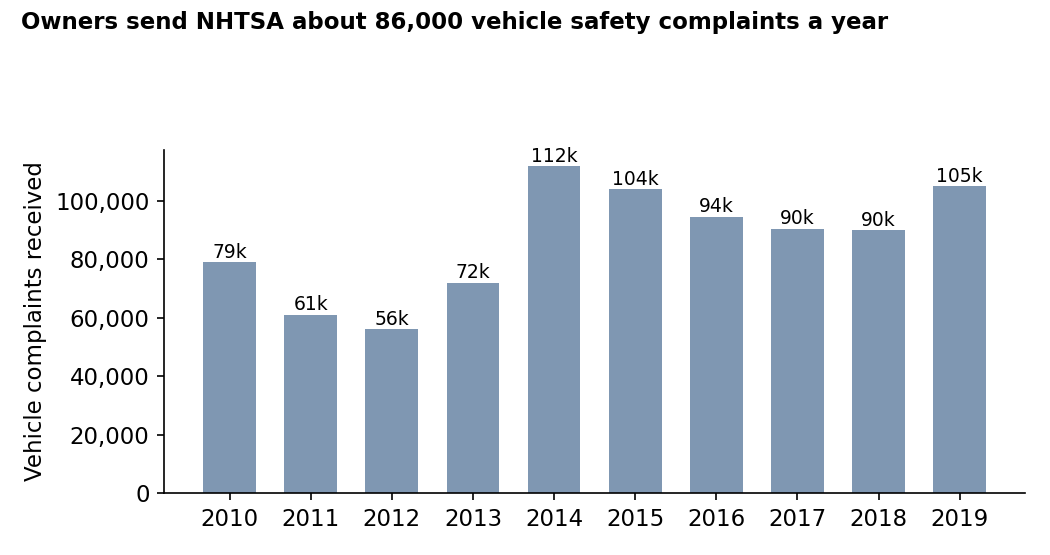

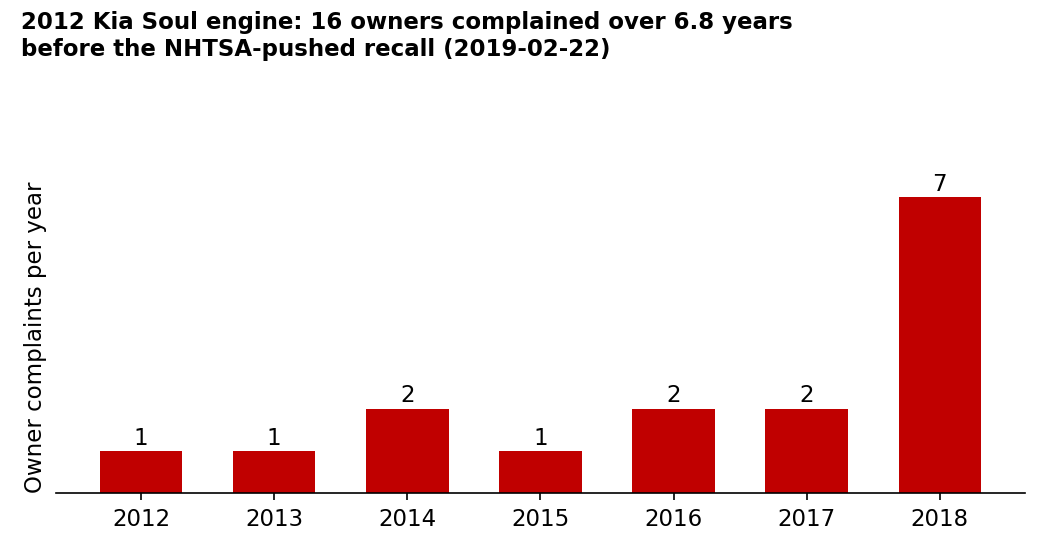

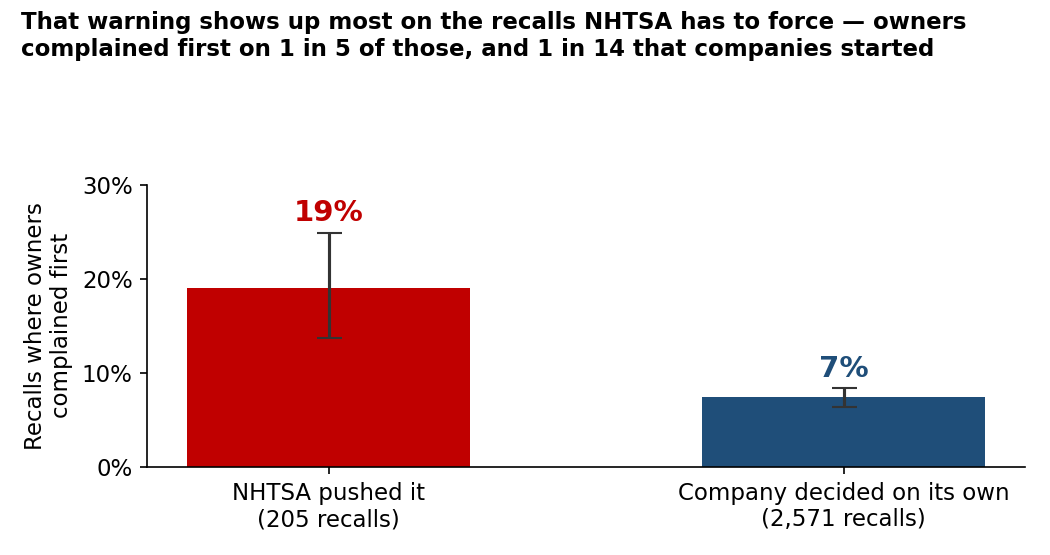

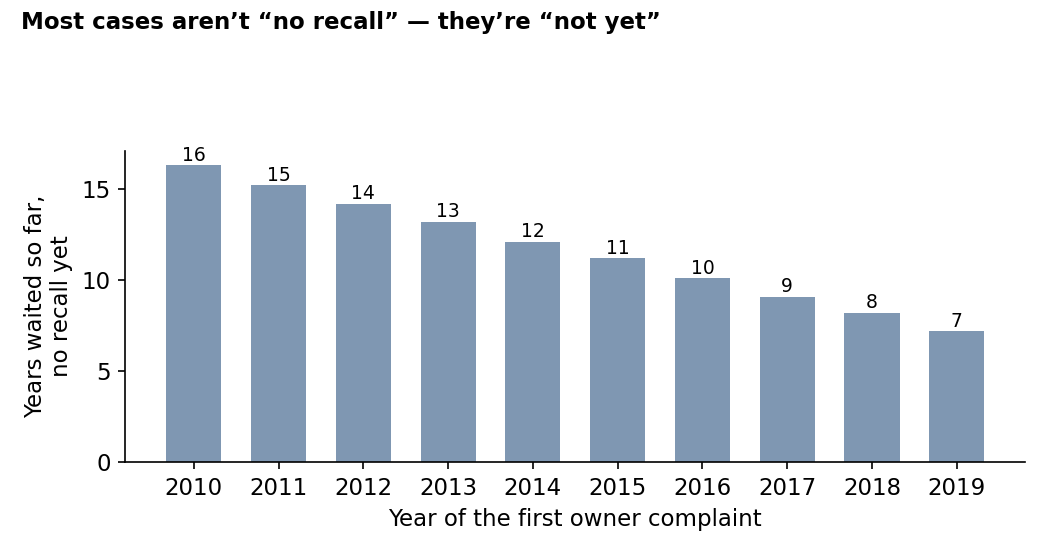

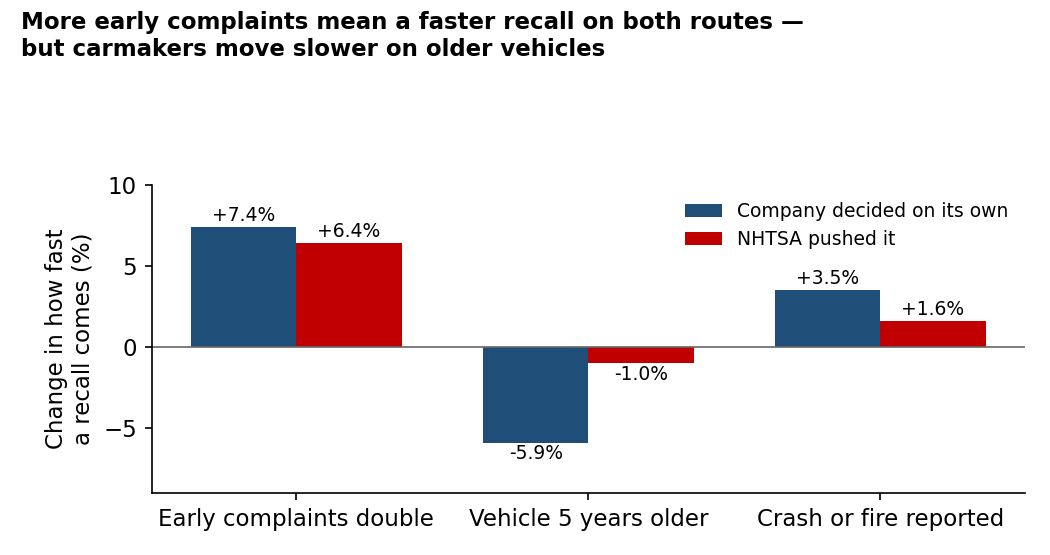

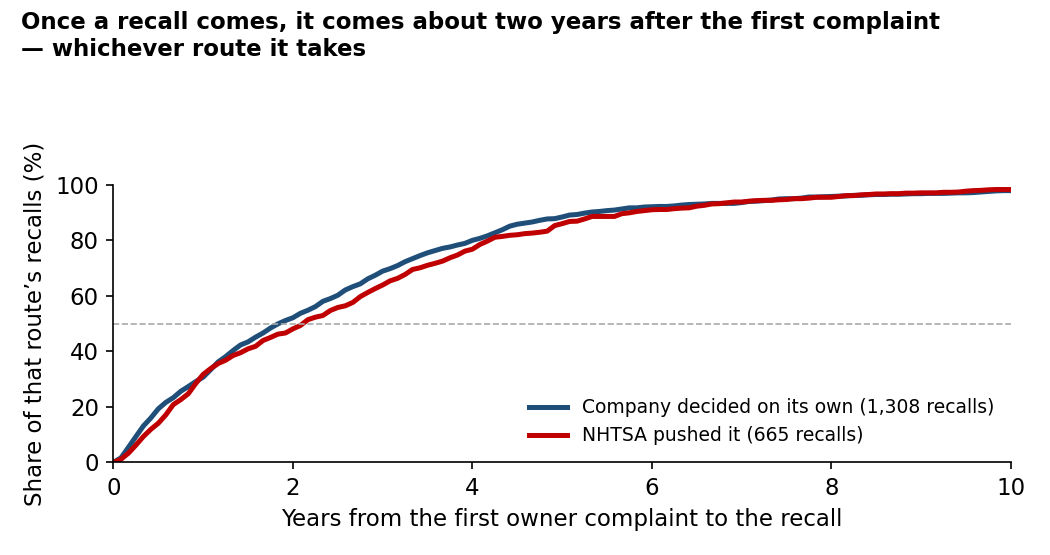

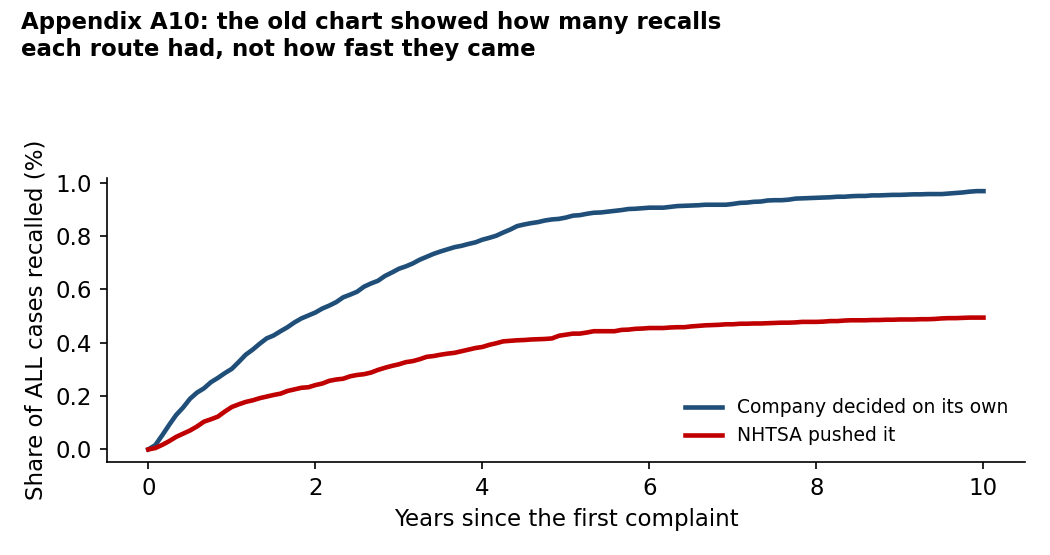

In [22]:
from IPython.display import Image, display
o = OUTPUT_DIR
files = [
    (complaints_per_year, (R["data"]["per_year"],), "slide2_complaints_per_year.png"),
    (case_study, (R["kia"],), "slide4_kia_soul.png"),
    (warning_rate, (R["warning"],), "slide5_warning_rate.png"),
    (years_waited, (R["waiting"],), "slide6_years_waited.png"),
    (speed_factors, (R["plain"],), "slide7_speed_factors.png"),
    (recall_timing, (R["timing"]["cdf"], R["timing"]), "slide8_recall_timing.png"),
    (old_route_chart_png, (R["old_chart"],), "appendixA10_old_chart.png"),
]
for fn, args, name in files:
    fn(*args, o / name)
    display(Image(filename=str(o / name)))

## Step 12 · Two checks added for the final deck (appendix A5 and A6)
**Late complaints.** Some complaints could be owners reacting to an investigation or a news story shortly before the recall. The files have no investigation-open date, so a complaint only counts as a warning if it came at least N months before the recall.

**The monthly list.** A backtest of the recommended next step: list a vehicle-and-part the first time it reaches X complaints within six months, then look 36 months ahead.

In [23]:
"""Two checks added for the final presentation.

1. late_complaints(): is the 19% warning rate on NHTSA-pushed recalls just
   owners reacting to an investigation or news story that came shortly
   before the recall? The files carry no investigation-open date, so this
   uses a buffer: a complaint only counts as a warning if it arrived at
   least N months before the recall. If the 19% were mostly reaction
   complaints, it would collapse as N grows.

2. monthly_list(): a backtest of the recommended next step. Each month,
   put a vehicle-and-part on the list the first time it collects X
   complaints inside six months. Then look 36 months ahead: how often did
   a listed vehicle get a defect recall, how much earlier than the recall
   was it listed, and how long is the list each month?
"""
import numpy as np
import pandas as pd

# summarize() is defined in Step 3 above

MONTH = pd.Timedelta(days=30.44)


def late_complaints(complaints, recalls, buffers=(0, 3, 6, 12, 24), start=2016, end=2019, n_boot=2000):
    c = complaints[["KEY", "received"]].dropna().sort_values("received")
    r = recalls[recalls["recall_date"].dt.year.between(start, end)
                & recalls["FMVSS"].isna()].drop_duplicates(["CAMPNO", "KEY"]).copy()
    r["airbag"] = r["KEY"].str.split("|").str[3].str.startswith("AIR BAGS")
    first = c.groupby("KEY")["received"].min()
    out = {}
    for n in buffers:
        cutoff = r["recall_date"] - n * MONTH
        r["prior"] = r["KEY"].map(first) < cutoff
        camp = r.groupby("CAMPNO").agg(route=("INFLUENCED_BY", "first"),
                                       prior=("prior", "max"), airbag=("airbag", "max"))
        camp = camp[camp["route"].isin(["MFR", "ODI"])]
        out[str(n)] = summarize(camp, n_boot=n_boot)
    return out


def _flag_dates(c, x, window_days):
    """First date each case reaches x complaints inside a rolling window."""
    if x == 1:
        return c.groupby("KEY")["received"].min()
    back = c.groupby("KEY")["received"].shift(x - 1)
    hit = (c["received"] - back).dt.days <= window_days
    return c[hit].groupby("KEY")["received"].min()


def monthly_list(complaints, recalls, thresholds=(1, 3, 5, 10), window_days=182, horizon=36,
                 start="2015-01-01", end="2019-12-31"):
    c = complaints[["KEY", "received"]].dropna().sort_values(["KEY", "received"])
    defect = recalls[recalls["FMVSS"].isna() & recalls["INFLUENCED_BY"].isin(["MFR", "ODI"])]
    rd = defect[["KEY", "recall_date", "INFLUENCED_BY"]].drop_duplicates()
    months = (pd.Timestamp(end) - pd.Timestamp(start)).days / 30.44
    out = {}
    for x in thresholds:
        f = _flag_dates(c, x, window_days)
        f = f[(f >= start) & (f <= end)].rename("flag").reset_index()
        m = f.merge(rd, on="KEY", how="left")
        already = m[m["recall_date"] <= m["flag"]]["KEY"].unique()
        m = m[~m["KEY"].isin(already)]
        f = f[~f["KEY"].isin(already)]
        ahead = m[(m["recall_date"] > m["flag"]) & (m["recall_date"] <= m["flag"] + horizon * MONTH)]
        ahead = ahead.sort_values("recall_date").drop_duplicates("KEY")
        lead = (ahead["recall_date"] - ahead["flag"]).dt.days / 30.44
        out[str(x)] = {"listed": int(len(f)), "per_month": round(len(f) / months, 1),
                       "recalled_36mo": int(len(ahead)),
                       "hit_rate": round(len(ahead) / len(f) * 100, 2),
                       "median_lead_months": round(float(lead.median()), 1),
                       "nhtsa_pushed_share": round(float((ahead["INFLUENCED_BY"] == "ODI").mean() * 100), 1)}
    base = out["1"]["hit_rate"]
    for x in out:
        out[x]["lift"] = round(out[x]["hit_rate"] / base, 1)
    # of the cases that did get a recall within 36 months of their first complaint,
    # how many would each list have caught before the recall?
    all_hits = out["1"]["recalled_36mo"]
    for x in thresholds:
        out[str(x)]["share_of_recalls_caught"] = round(out[str(x)]["recalled_36mo"] / all_hits * 100, 1)
    return out

In [24]:
R["checks"] = {"late_complaints": late_complaints(complaints, recalls),
               "monthly_list": monthly_list(complaints, recalls)}
for n, s in R["checks"]["late_complaints"].items():
    print(f"complaint at least {n:>2} months before recall: NHTSA {s['ODI']['rate']}% [{s['ODI']['lo']}, {s['ODI']['hi']}] | "
          f"company {s['MFR']['rate']}% | gap {s['gap']['mean']} [{s['gap']['lo']}, {s['gap']['hi']}]")
for x, s in R["checks"]["monthly_list"].items():
    print(f"list at {x:>2} complaints in 6 months: {s['per_month']} a month, {s['hit_rate']}% recalled within 3 years "
          f"({s['lift']}x average), median {s['median_lead_months']} months before the recall")

complaint at least  0 months before recall: NHTSA 19.0% [13.7, 24.9] | company 7.4% | gap 11.5 [6.1, 17.2]
complaint at least  3 months before recall: NHTSA 18.5% [13.2, 24.4] | company 6.7% | gap 11.8 [6.3, 17.4]
complaint at least  6 months before recall: NHTSA 17.6% [12.2, 23.4] | company 6.3% | gap 11.1 [5.8, 16.6]
complaint at least 12 months before recall: NHTSA 16.6% [11.7, 22.0] | company 5.8% | gap 10.7 [5.6, 16.2]
complaint at least 24 months before recall: NHTSA 12.7% [8.3, 17.6] | company 4.0% | gap 8.6 [4.0, 13.7]
list at  1 complaints in 6 months: 766.6 a month, 0.81% recalled within 3 years (1.0x average), median 14.4 months before the recall
list at  3 complaints in 6 months: 162.7 a month, 1.46% recalled within 3 years (1.8x average), median 13.9 months before the recall
list at  5 complaints in 6 months: 85.3 a month, 1.97% recalled within 3 years (2.4x average), median 14.7 months before the recall
list at 10 complaints in 6 months: 34.5 a month, 2.95% recalled withi

## Step 13 · Save everything, and check it against the expected numbers

In [25]:
(OUTPUT_DIR / "results.json").write_text(json.dumps(R, indent=1))
print(f"saved {OUTPUT_DIR / 'results.json'}  ({(time.time() - T0) / 60:.1f} min total)\n")

checks = [
    ("Vehicle complaints, valid model year", R["data"]["vehicle_complaints_valid_year"], 863352),
    ("Cases", R["data"]["cases"], 133053),
    ("Company recalls", int(R["cox"]["company"]["events"]), 1308),
    ("NHTSA-pushed recalls", int(R["cox"]["nhtsa"]["events"]), 665),
    ("Still waiting %", R["data"]["still_waiting_pct"], 98.5),
    ("Warning rate overall %", R["warning"]["overall"]["rate"], 8.2),
    ("Warning rate NHTSA-pushed %", R["warning"]["ODI"]["rate"], 19.0),
    ("Warning rate company %", R["warning"]["MFR"]["rate"], 7.4),
    ("Gap (points)", R["warning"]["gap"]["mean"], 11.5),
    ("Median months, company", R["timing"]["MFR"]["median"], 22.0),
    ("Median months, NHTSA", R["timing"]["ODI"]["median"], 25.5),
    ("Cox company: complaint volume", R["cox"]["company"]["rows"]["complaint_volume_log"]["hr"], 1.108),
    ("Cox company: vehicle age", R["cox"]["company"]["rows"]["vehicle_age"]["hr"], 0.988),
    ("Cox NHTSA: complaint volume", R["cox"]["nhtsa"]["rows"]["complaint_volume_log"]["hr"], 1.094),
    ("Cox NHTSA: vehicle age", R["cox"]["nhtsa"]["rows"]["vehicle_age"]["hr"], 0.998),
    ("Kia Soul complaints before recall", R["kia"]["complaints_before_recall"], 16),
]
checks += [
    ("NHTSA rate, 12-month buffer %", R["checks"]["late_complaints"]["12"]["ODI"]["rate"], 16.6),
    ("Company rate, 12-month buffer %", R["checks"]["late_complaints"]["12"]["MFR"]["rate"], 5.8),
    ("List at 10: vehicles a month", R["checks"]["monthly_list"]["10"]["per_month"], 34.5),
    ("List at 10: median lead, months", R["checks"]["monthly_list"]["10"]["median_lead_months"], 17.3),
]
if "classifier" in R:
    checks.append(("Best classifier PR-AUC", max(m["pr_auc"] for m in R["classifier"]["models"]), 0.0254))
ok = 0
for label, got, want in checks:
    match = abs(float(got) - float(want)) <= max(0.0011, abs(float(want)) * 0.002)
    ok += match
    print(f"{'OK ' if match else 'XX '} {label:38s} got {got:<10} expected {want}")
print(f"\n{ok} of {len(checks)} match.")

saved output/results.json  (3.8 min total)

OK  Vehicle complaints, valid model year   got 863352     expected 863352
OK  Cases                                  got 133053     expected 133053
OK  Company recalls                        got 1308       expected 1308
OK  NHTSA-pushed recalls                   got 665        expected 665
OK  Still waiting %                        got 98.5       expected 98.5
OK  Warning rate overall %                 got 8.2        expected 8.2
OK  Warning rate NHTSA-pushed %            got 19.0       expected 19.0
OK  Warning rate company %                 got 7.4        expected 7.4
OK  Gap (points)                           got 11.5       expected 11.5
OK  Median months, company                 got 22.0       expected 22.0
OK  Median months, NHTSA                   got 25.5       expected 25.5
OK  Cox company: complaint volume          got 1.108      expected 1.108
OK  Cox company: vehicle age               got 0.988      expected 0.988
OK  Cox NHTSA: co